In [5]:
from google.colab import files
uploaded = files.upload()

Saving churn-20261021T072951Z-1-001.zip to churn-20261021T072951Z-1-001.zip


In [6]:
import os
import zipfile
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Giải nén file ZIP vừa tải lên
zip_name = next(iter(uploaded.keys()))

with zipfile.ZipFile(zip_name, "r") as z:
    z.extractall("/content")

# Đọc dữ liệu
DATA_DIR = "/content/churn"

train = pd.read_csv(f"{DATA_DIR}/train.csv")

print("Kích thước dữ liệu:", train.shape)
print("\nTên các cột:")
print(train.columns.tolist())

display(train.head())

Kích thước dữ liệu: (12120, 24)

Tên các cột:
['customer_id', 'bank_code', 'age', 'gender', 'province', 'occupation', 'income_month', 'card_type', 'open_date', 'credit_limit', 'annual_fee_waived', 'utilization_6m', 'txn_count_3m', 'txn_amount_3m', 'spend_change_pct', 'app_logins_30d', 'complaints_12m', 'late_payments_12m', 'salary_via_bank', 'other_bank_cards', 'promo_ended_60d', 'last_contact_channel', 'currency', 'churn_3m']


,customer_id,bank_code,age,gender,province,occupation,income_month,card_type,open_date,credit_limit,...,spend_change_pct,app_logins_30d,complaints_12m,late_payments_12m,salary_via_bank,other_bank_cards,promo_ended_60d,last_contact_channel,currency,churn_3m
0,CUSTI3FNUD,VB01,48.0,F,Hải Dương,self_employed,25.1,Gold,2026-04-09,55.0,...,-23.5,2.0,0,0,N,1.0,0,app,vnd,1
1,CUSOOYRASU,VB01,47.0,M,Hà Nội,Salaried,NaN,Classic,06/01/2024,30.0,...,-27.7,4.0,0,0,Y,1.0,0,app,VND,0
2,CUSQTUBJRJ,VB01,38.0,M,Long An,other,8.5,Cashback,02/08/2022,15.0,...,-20.7,8.0,0,0,N,0.0,1,none,VND,0
3,CUSD7I53QY,VB01,25.0,M,TP.HCM,self_employed,33.9,Cashback,12/05/2022,110.0,...,44.7,5.0,0,0,N,NaN,1,app,VND,0
4,CUS02NC6FN,VB01,32.0,m,TP.HCM,civil_servant,14.0,Cashback,03/07/2025,40.0,...,-28.0,4.0,0,0,N,0.0,0,none,VND,0


=== KIỂU DỮ LIỆU ===


,data_type
customer_id,object
bank_code,object
age,float64
gender,object
province,object
occupation,object
income_month,float64
card_type,object
open_date,object
credit_limit,float64


=== THỐNG KÊ DỮ LIỆU SỐ ===


,count,mean,std,min,25%,50%,75%,max
age,11724.0,3.974326e+01,2.993628e+01,0.00,31.0000,38.000,45.0000,9.990000e+02
income_month,10558.0,1.875843e+05,2.065907e+06,1.00,11.8000,17.700,26.1000,5.050000e+07
credit_limit,12120.0,1.094113e+06,1.052716e+07,10.00,25.0000,40.000,70.0000,3.850000e+08
annual_fee_waived,12120.0,5.075908e-01,4.999630e-01,0.00,0.0000,1.000,1.0000,1.000000e+00
utilization_6m,12120.0,3.248559e-01,7.247546e-01,-1.00,0.1380,0.272,0.4210,1.500000e+01
txn_count_3m,12120.0,1.891147e+01,1.026963e+01,1.00,12.0000,17.000,24.0000,1.010000e+02
txn_amount_3m,12120.0,2.534355e+01,2.880579e+01,-2.99,8.7175,16.760,31.6325,4.628100e+02
spend_change_pct,12120.0,-1.015182e-01,2.485480e+01,-95.00,-16.9000,-0.000,16.6000,1.058000e+02
app_logins_30d,10604.0,6.374010e+00,4.634716e+00,0.00,3.0000,5.000,8.0000,4.800000e+01
complaints_12m,12120.0,2.505776e-01,5.021610e-01,0.00,0.0000,0.000,0.0000,3.000000e+00


=== MISSING VALUES ===


,missing_count,missing_percent
other_bank_cards,2463,20.32
income_month,1562,12.89
app_logins_30d,1516,12.51
salary_via_bank,718,5.92
occupation,614,5.07
last_contact_channel,515,4.25
age,396,3.27
gender,231,1.91
province,201,1.66
open_date,78,0.64


Số dòng trùng hoàn toàn: 120
Số customer_id trùng: 120
=== PHÂN PHỐI CHURN ===


,count
churn_3m,
0,10707
1,1413


Tỷ lệ churn (%):


,proportion
churn_3m,
0,88.34
1,11.66


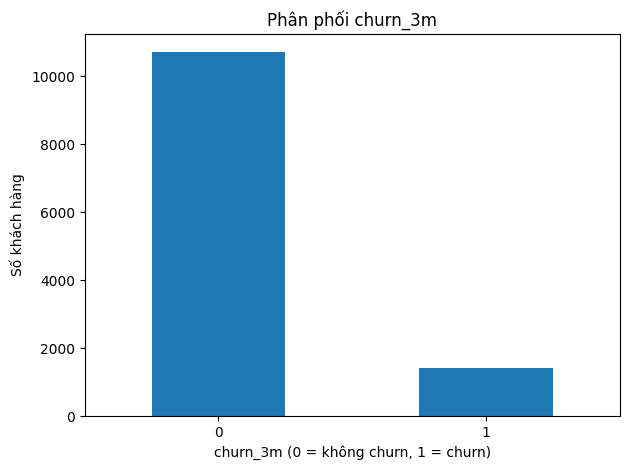

In [7]:
# Kiểu dữ liệu
print("=== KIỂU DỮ LIỆU ===")
display(train.dtypes.rename("data_type").to_frame())

# Thống kê dữ liệu số
print("=== THỐNG KÊ DỮ LIỆU SỐ ===")
display(train.describe().T)

# Số lượng và tỷ lệ ô thiếu
missing = pd.DataFrame({
    "missing_count": train.isna().sum(),
    "missing_percent": (train.isna().mean() * 100).round(2)
}).sort_values("missing_percent", ascending=False)

print("=== MISSING VALUES ===")
display(missing[missing["missing_count"] > 0])

# Dòng trùng lặp
print("Số dòng trùng hoàn toàn:", train.duplicated().sum())
print("Số customer_id trùng:", train["customer_id"].duplicated().sum())

# Phân phối biến mục tiêu
print("=== PHÂN PHỐI CHURN ===")
display(
    train["churn_3m"]
    .value_counts(dropna=False)
    .rename_axis("churn_3m")
    .to_frame("count")
)

print("Tỷ lệ churn (%):")
display((train["churn_3m"].value_counts(normalize=True) * 100).round(2))

# Biểu đồ tỷ lệ churn
train["churn_3m"].value_counts().sort_index().plot(
    kind="bar", rot=0, title="Phân phối churn_3m"
)
plt.xlabel("churn_3m (0 = không churn, 1 = churn)")
plt.ylabel("Số khách hàng")
plt.tight_layout()
plt.show()

In [11]:
import pandas as pd
import re
import unicodedata

# Chuẩn hóa khoảng trắng và các giá trị chữ
text_cols = train.select_dtypes(include=["object", "string"]).columns

for col in text_cols:
    train[col] = train[col].astype("string").str.strip()


# =========================
# 1. CHUẨN HÓA GENDER
# =========================
if "gender" in train.columns:
    gender_map = {
        "F": "F",
        "FEMALE": "F",
        "NỮ": "F",
        "NU": "F",
        "M": "M",
        "MALE": "M",
        "NAM": "M"
    }

    train["gender"] = (
        train["gender"]
        .str.strip()
        .str.upper()
        .replace(gender_map)
    )

    # Các giá trị không hợp lệ chuyển thành NA
    train.loc[~train["gender"].isin(["F", "M"]), "gender"] = pd.NA


# =========================
# 2. HÀM CHUẨN HÓA TÊN
# =========================
def normalize_name(value):
    if pd.isna(value):
        return None

    value = str(value).strip().lower()
    value = unicodedata.normalize("NFD", value)
    value = "".join(
        c for c in value
        if unicodedata.category(c) != "Mn"
    )
    value = value.replace("đ", "d")
    value = re.sub(r"[.\-_]", " ", value)
    value = re.sub(r"\s+", " ", value).strip()

    return value


# =========================
# 3. CHUẨN HÓA PROVINCE
# =========================
if "province" in train.columns:

    province_map = {
        # TP. Hồ Chí Minh
        "hcm": "HCM",
        "tp hcm": "HCM",
        "tphcm": "HCM",
        "tp ho chi minh": "HCM",
        "thanh pho ho chi minh": "HCM",
        "ho chi minh": "HCM",
        "ho chi minh city": "HCM",
        "sai gon": "HCM",

        # Hà Nội
        "ha noi": "Hà Nội",
        "hn": "Hà Nội",
        "hanoi": "Hà Nội",
        "thu do ha noi": "Hà Nội",

        # Đà Nẵng
        "da nang": "Đà Nẵng",
        "danang": "Đà Nẵng",

        # Bà Rịa - Vũng Tàu
        "ba ria vung tau": "Bà Rịa - Vũng Tàu",
        "br vt": "Bà Rịa - Vũng Tàu",
        "brvt": "Bà Rịa - Vũng Tàu",

        # Huế
        "hue": "Thừa Thiên Huế",
        "thua thien hue": "Thừa Thiên Huế",
        "thuathienhue": "Thừa Thiên Huế",
        "tt hue": "Thừa Thiên Huế",
        "tt-hue": "Thừa Thiên Huế",

        # Các tỉnh có dấu và không dấu
        "hai phong": "Hải Phòng",
        "binh duong": "Bình Dương",
        "can tho": "Cần Thơ",
        "dong nai": "Đồng Nai",
        "khanh hoa": "Khánh Hòa",
        "quang ninh": "Quảng Ninh",
        "nghe an": "Nghệ An",
        "bac ninh": "Bắc Ninh",
        "thanh hoa": "Thanh Hóa",
        "hai duong": "Hải Dương",
        "lam dong": "Lâm Đồng",
        "thua thien hue": "Thừa Thiên Huế",
        "thai nguyen": "Thái Nguyên",
        "nam dinh": "Nam Định",
        "long an": "Long An",
        "binh dinh": "Bình Định"
    }

    # Tạo mapping tự động cho tên có dấu, không dấu,
    # viết hoa, viết thường và dấu chấm/gạch
    normalized_map = {
        normalize_name(key): value
        for key, value in province_map.items()
    }

    # Bổ sung tên chuẩn để xử lý dữ liệu vốn đã có dấu
    canonical_names = [
        "HCM", "Hà Nội", "Hải Phòng", "Đà Nẵng",
        "Bình Dương", "Cần Thơ", "Đồng Nai", "Khánh Hòa",
        "Quảng Ninh", "Nghệ An", "Bắc Ninh", "Thanh Hóa",
        "Hải Dương", "Lâm Đồng", "Thừa Thiên Huế",
        "Thái Nguyên", "Nam Định", "Bà Rịa - Vũng Tàu",
        "Long An", "Bình Định"
    ]

    for name in canonical_names:
        normalized_map[normalize_name(name)] = name

    train["province"] = train["province"].apply(
        lambda x: (
            pd.NA if pd.isna(x) or str(x).strip() == ""
            else normalized_map.get(normalize_name(x), str(x).strip())
        )
    )


# =========================
# 4. KIỂM TRA KẾT QUẢ
# =========================
if "gender" in train.columns:
    print("Gender sau chuẩn hóa:")
    display(train["gender"].value_counts(dropna=False))

if "province" in train.columns:
    print("Province sau chuẩn hóa:")
    display(train["province"].value_counts(dropna=False))

    print("\nCác giá trị province còn lại cần kiểm tra:")
    display(
        train.loc[
            train["province"].notna(),
            "province"
        ].value_counts().to_frame("count")
    )

    print("\nSố lượng province khác nhau:",
          train["province"].nunique(dropna=True))

    print("Số province bị thiếu:",
          train["province"].isna().sum())

Gender sau chuẩn hóa:


,count
gender,
F,6371
M,5518
<NA>,231


Province sau chuẩn hóa:


,count
province,
HCM,3758
Hà Nội,3665
Đà Nẵng,703
Hải Phòng,639
Bình Dương,424
Cần Thơ,408
Đồng Nai,293
Khánh Hòa,236
Quảng Ninh,206



Các giá trị province còn lại cần kiểm tra:


,count
province,
HCM,3758
Hà Nội,3665
Đà Nẵng,703
Hải Phòng,639
Bình Dương,424
Cần Thơ,408
Đồng Nai,293
Khánh Hòa,236
Quảng Ninh,206



Số lượng province khác nhau: 25
Số province bị thiếu: 201


In [12]:
# 1. Phân tích ô trống
missing_cols = ["other_bank_cards", "income_month", "app_logins_30d"]

for col in missing_cols:
    if col in train.columns:
        print(f"{col}: {train[col].isna().sum()} ô thiếu "
              f"({train[col].isna().mean() * 100:.2f}%)")

# 2. Kiểm tra tuổi bất thường
if "age" in train.columns:
    print("\nTuổi nhỏ hơn 18:")
    display(train.loc[train["age"] < 18, ["customer_id", "age"]].head(10))

    print("\nTuổi từ 100 trở lên:")
    display(train.loc[train["age"] >= 100, ["customer_id", "age"]].head(20))

# 3. Kiểm tra thu nhập âm
if "income_month" in train.columns:
    print("\nSố thu nhập âm:", (train["income_month"] < 0).sum())
    display(train.loc[train["income_month"] < 0,
                      ["customer_id", "income_month"]].head(10))

# 4. Kiểm tra số thẻ ngân hàng khác âm
if "other_bank_cards" in train.columns:
    print("\nSố giá trị other_bank_cards âm:",
          (train["other_bank_cards"] < 0).sum())
    display(train.loc[train["other_bank_cards"] < 0,
                      ["customer_id", "other_bank_cards"]].head(10))

# 5. Kiểm tra các cột số khác
for col in ["credit_limit", "txn_count_3m", "txn_amount_3m",
            "app_logins_30d", "complaints_12m", "late_payments_12m"]:
    if col in train.columns:
        print(f"{col}: {(train[col] < 0).sum()} giá trị âm")

other_bank_cards: 2463 ô thiếu (20.32%)
income_month: 1562 ô thiếu (12.89%)
app_logins_30d: 1516 ô thiếu (12.51%)

Tuổi nhỏ hơn 18:


,customer_id,age
19,CUS81NKL9A,0.0
189,CUS907WOXD,0.0
361,CUSX9QIULQ,0.0
792,CUSL31B6FM,1.0
1245,CUSGJX9NLU,1.0
1411,CUS55A5VSE,0.0
1674,CUS0ZFD150,0.0
3656,CUSMBF27QY,1.0
3745,CUSBYCWMQE,1.0
4205,CUSYHGJ4TU,1.0



Tuổi từ 100 trở lên:


,customer_id,age
20,CUSFC88SRR,150.0
354,CUSFM7CGHG,150.0
483,CUSBHH33UB,150.0
506,CUSUGXDPKN,150.0
717,CUS1PO8KBA,200.0
815,CUSJPRID9S,150.0
828,CUSTUYLEIF,200.0
1273,CUS7GNOBPS,200.0
1730,CUSMWR53PI,150.0
2299,CUS82YJI5W,150.0



Số thu nhập âm: 0


,customer_id,income_month



Số giá trị other_bank_cards âm: 0


,customer_id,other_bank_cards


credit_limit: 0 giá trị âm
txn_count_3m: 0 giá trị âm
txn_amount_3m: 170 giá trị âm
app_logins_30d: 0 giá trị âm
complaints_12m: 0 giá trị âm
late_payments_12m: 0 giá trị âm


In [13]:
# Kiểm tra định dạng ngày mở tài khoản
print("Một số giá trị open_date:")
display(train["open_date"].value_counts(dropna=False).head(15))

# Chuẩn hóa ngày có nhiều định dạng
train["open_date"] = pd.to_datetime(
    train["open_date"],
    format="mixed",
    dayfirst=True,
    errors="coerce"
)

print("Số ngày mở tài khoản không đọc được:",
      train["open_date"].isna().sum())

# Tỷ lệ churn theo giới tính
if "gender" in train.columns:
    print("\nTỷ lệ churn theo gender:")
    display(
        train.groupby("gender", dropna=False)["churn_3m"]
        .agg(["count", "mean"])
        .assign(churn_percent=lambda x: (x["mean"] * 100).round(2))
    )

# Tỷ lệ churn theo nghề nghiệp
if "occupation" in train.columns:
    print("\nTỷ lệ churn theo occupation:")
    display(
        train.groupby("occupation", dropna=False)["churn_3m"]
        .agg(["count", "mean"])
        .assign(churn_percent=lambda x: (x["mean"] * 100).round(2))
        .sort_values("churn_percent", ascending=False)
    )

# Tỷ lệ churn theo kênh liên hệ gần nhất
if "last_contact_channel" in train.columns:
    print("\nTỷ lệ churn theo last_contact_channel:")
    display(
        train.groupby("last_contact_channel", dropna=False)["churn_3m"]
        .agg(["count", "mean"])
        .assign(churn_percent=lambda x: (x["mean"] * 100).round(2))
        .sort_values("churn_percent", ascending=False)
    )

# So sánh churn theo việc kết thúc khuyến mãi gần đây
if "promo_ended_60d" in train.columns:
    print("\nTỷ lệ churn theo promo_ended_60d:")
    display(
        train.groupby("promo_ended_60d", dropna=False)["churn_3m"]
        .agg(["count", "mean"])
        .assign(churn_percent=lambda x: (x["mean"] * 100).round(2))
    )

Một số giá trị open_date:


,count
open_date,
<NA>,78
2025-05-03,17
2022-07-09,16
2024-07-10,15
2024-05-24,15
2024-08-31,15
2025-03-27,15
2025-10-11,15
2024-12-06,14


Số ngày mở tài khoản không đọc được: 78

Tỷ lệ churn theo gender:


,count,mean,churn_percent
gender,,,
F,6371,0.121017,12.10
M,5518,0.111816,11.18
<NA>,231,0.108225,10.82



Tỷ lệ churn theo occupation:


,count,mean,churn_percent
occupation,,,
Retired,130,0.400000,40.00
retired,718,0.363510,36.35
Student,52,0.211538,21.15
student,281,0.202847,20.28
<NA>,614,0.133550,13.36
Salaried,262,0.114504,11.45
self_employed,2098,0.102002,10.20
other,998,0.101202,10.12
salaried,4934,0.088569,8.86



Tỷ lệ churn theo last_contact_channel:


,count,mean,churn_percent
last_contact_channel,,,
branch,2352,0.121173,12.12
hotline,1388,0.118876,11.89
app,4433,0.118204,11.82
none,3432,0.111597,11.16
<NA>,515,0.108738,10.87



Tỷ lệ churn theo promo_ended_60d:


,count,mean,churn_percent
promo_ended_60d,,,
0,9748,0.094584,9.46
1,2372,0.206998,20.70


In [14]:

%%writefile /content/clean_data.py
import pandas as pd
import numpy as np


def clean_data(df):
    """Làm sạch dữ liệu churn, giữ lại cờ báo ô thiếu và giá trị bất thường."""
    df = df.copy()

    # 1. Chuẩn hóa chuỗi
    text_cols = df.select_dtypes(include=["object", "string"]).columns
    for col in text_cols:
        df[col] = df[col].astype("string").str.strip()

    # 2. Chuẩn hóa gender
    if "gender" in df.columns:
        gender_map = {
            "F": "F", "FEMALE": "F", "NỮ": "F", "NU": "F",
            "M": "M", "MALE": "M", "NAM": "M"
        }
        df["gender"] = (
            df["gender"].str.upper().replace(gender_map)
        )

    # 3. Chuẩn hóa province
    if "province" in df.columns:
        province_map = {
            "TP.HCM": "HCM",
            "TP HCM": "HCM",
            "TP. HCM": "HCM",
            "THÀNH PHỐ HỒ CHÍ MINH": "HCM",
            "HỒ CHÍ MINH": "HCM",
            "HO CHI MINH": "HCM",
            "BÀ RỊA VŨNG TÀU": "Bà Rịa - Vũng Tàu",
            "BÀ RỊA-VŨNG TÀU": "Bà Rịa - Vũng Tàu",
            "BA RIA VUNG TAU": "Bà Rịa - Vũng Tàu"
        }
        df["province"] = df["province"].replace(province_map)

    # 4. Chuyển cột số về kiểu numeric nếu cần
    numeric_cols = [
        "age", "income_month", "other_bank_cards",
        "credit_limit", "utilization_6m", "txn_count_3m",
        "txn_amount_3m", "spend_change_pct", "app_logins_30d",
        "complaints_12m", "late_payments_12m"
    ]

    for col in numeric_cols:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors="coerce")

    # 5. Lưu dấu ô thiếu ban đầu
    for col in ["age", "income_month", "other_bank_cards",
                "app_logins_30d", "occupation", "salary_via_bank",
                "last_contact_channel"]:
        if col in df.columns:
            df[f"{col}_was_missing"] = df[col].isna().astype("int8")

    # 6. Đánh dấu và xử lý giá trị bất thường
    if "age" in df.columns:
        df["age_outlier_flag"] = (
            (df["age"] < 18) | (df["age"] > 100)
        ).astype("int8")
        df.loc[(df["age"] < 18) | (df["age"] > 100), "age"] = np.nan

    for col in ["income_month", "other_bank_cards"]:
        if col in df.columns:
            df[f"{col}_invalid_flag"] = (df[col] < 0).astype("int8")
            df.loc[df[col] < 0, col] = np.nan

    # Những biến đếm không thể âm
    for col in ["txn_count_3m", "app_logins_30d",
                "complaints_12m", "late_payments_12m"]:
        if col in df.columns:
            df[f"{col}_invalid_flag"] = (df[col] < 0).astype("int8")
            df.loc[df[col] < 0, col] = np.nan

    # Các giá trị tỷ lệ sử dụng thẻ phải nằm trong [0, 1]
    if "utilization_6m" in df.columns:
        invalid = ~df["utilization_6m"].between(0, 1)
        df["utilization_6m_invalid_flag"] = invalid.astype("int8")
        df.loc[invalid, "utilization_6m"] = np.nan

    # 7. Chuẩn hóa ngày; ngày không đọc được trở thành NaT
    if "open_date" in df.columns:
        df["open_date"] = pd.to_datetime(
            df["open_date"],
            format="mixed",
            dayfirst=True,
            errors="coerce"
        )

    # 8. Điền thiếu cho biến số bằng trung vị
    # Không điền biến mục tiêu churn_3m hoặc các cột ID
    exclude = {"churn_3m", "customer_id"}
    for col in df.select_dtypes(include="number").columns:
        if col not in exclude and df[col].isna().any():
            median_value = df[col].median()
            if pd.notna(median_value):
                df[col] = df[col].fillna(median_value)

    # 9. Điền thiếu cho biến phân loại
    for col in df.select_dtypes(include=["object", "string"]).columns:
        if col not in exclude:
            df[col] = df[col].fillna("Unknown")

    return df


if __name__ == "__main__":
    input_path = "/content/churn/train.csv"
    output_path = "/content/cleaned_churn.csv"

    raw = pd.read_csv(input_path)
    cleaned = clean_data(raw)
    cleaned.to_csv(output_path, index=False)

    print("Kích thước ban đầu:", raw.shape)
    print("Kích thước sau làm sạch:", cleaned.shape)
    print("Số ô thiếu còn lại:")
    print(cleaned.isna().sum()[cleaned.isna().sum() > 0])
    print("Đã lưu:", output_path)


Writing /content/clean_data.py


In [15]:
import sys
sys.path.insert(0, "/content")

from clean_data import clean_data

cleaned = clean_data(pd.read_csv("/content/churn/train.csv"))

print("Kích thước sau làm sạch:", cleaned.shape)
print("Các cột đánh dấu bất thường:")
print([c for c in cleaned.columns if "flag" in c])

display(cleaned.head())

cleaned.to_csv("/content/cleaned_churn.csv", index=False)



Kích thước sau làm sạch: (12120, 39)
Các cột đánh dấu bất thường:
['age_outlier_flag', 'income_month_invalid_flag', 'other_bank_cards_invalid_flag', 'txn_count_3m_invalid_flag', 'app_logins_30d_invalid_flag', 'complaints_12m_invalid_flag', 'late_payments_12m_invalid_flag', 'utilization_6m_invalid_flag']


,customer_id,bank_code,age,gender,province,occupation,income_month,card_type,open_date,credit_limit,...,salary_via_bank_was_missing,last_contact_channel_was_missing,age_outlier_flag,income_month_invalid_flag,other_bank_cards_invalid_flag,txn_count_3m_invalid_flag,app_logins_30d_invalid_flag,complaints_12m_invalid_flag,late_payments_12m_invalid_flag,utilization_6m_invalid_flag
0,CUSTI3FNUD,VB01,48.0,F,Hải Dương,self_employed,25.1,Gold,2026-04-09,55.0,...,0,0,0,0,0,0,0,0,0,0
1,CUSOOYRASU,VB01,47.0,M,Hà Nội,Salaried,17.7,Classic,2024-01-06,30.0,...,0,0,0,0,0,0,0,0,0,0
2,CUSQTUBJRJ,VB01,38.0,M,Long An,other,8.5,Cashback,2022-08-02,15.0,...,0,0,0,0,0,0,0,0,0,0
3,CUSD7I53QY,VB01,25.0,M,HCM,self_employed,33.9,Cashback,2022-05-12,110.0,...,0,0,0,0,0,0,0,0,0,0
4,CUS02NC6FN,VB01,32.0,M,HCM,civil_servant,14.0,Cashback,2025-07-03,40.0,...,0,0,0,0,0,0,0,0,0,0


In [16]:
from google.colab import files

files.download("/content/clean_data.py")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>